In [15]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt

transform = transforms.ToTensor()

train_set = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_set  = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False)

images: torch.Size([64, 1, 28, 28])
labels: torch.Size([64])
train_set: 60000 | test_set: 10000
train_loader: 938
10 nhãn đầu: tensor([9, 0, 7, 4, 5, 3, 3, 4, 3, 9])
tên lớp: ['Ankle boot', 'T-shirt/top', 'Sneaker', 'Coat', 'Sandal', 'Dress', 'Dress', 'Coat', 'Dress', 'Ankle boot']


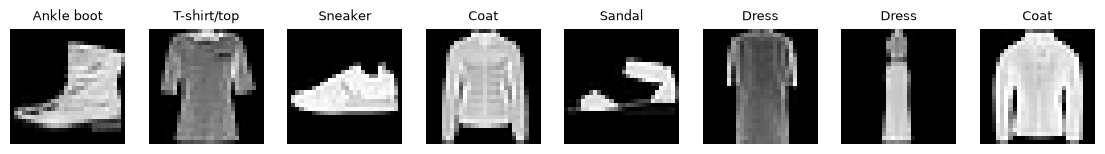

In [14]:
# 1. Lấy một batch
images, labels = next(iter(train_loader))

# 2. Shape
print("images:", images.shape)
print("labels:", labels.shape)

# 3. Số mẫu: len() trên Dataset và trên DataLoader
print("train_set:", len(train_set), "| test_set:", len(test_set))
print("train_loader:", len(train_loader))   # số batch, không phải số ảnh

# 4. Nhãn: số và tên lớp
print("10 nhãn đầu:", labels[:10])
print("tên lớp:", [train_set.classes[i] for i in labels[:10]])

# 5. Vẽ 8 ảnh đầu tiên
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")   # (1,28,28) -> (28,28)
    ax.set_title(train_set.classes[labels[i]], fontsize=9)
    ax.axis("off")
plt.show()

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()              # bắt buộc: khởi tạo phần của nn.Module
        self.input_dim = input_dim
        self.flatten = nn.Flatten()     # (N, 1, 28, 28) -> (N, 784)
        self.fc1 = nn.Linear(784, 256)  # lớp ẩn: 784 vào, 256 ra
        self.relu = nn.ReLU()           # phi tuyến
        self.fc2 = nn.Linear(256,10)    # lớp output: 10 lớp

        # Khởi tạo He cho mọi lớp Linear
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_uniform_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)                 # trả về logits, KHÔNG softmax
        return x

model = MLP()
print(model)

# Kiểm tra: đưa batch từ bước 1 vào
out = model(images)
print("output:", out.shape)

# Đếm tham số
total = sum(p.numel() for p in model.parameters())
print("số tham số:", total)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
output: torch.Size([64, 10])
số tham số: 203530


In [24]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

torch.manual_seed(42)                     # cố định ngẫu nhiên để lần chạy sau ra kết quả giống
model = MLP().to(device)                  # đưa mô hình lên GPU của Mac

criterion = nn.CrossEntropyLoss()         # gộp sẵn softmax + negative log-likelihood
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)   # đúng như slide

device: mps


In [25]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                                  # chế độ train
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)                     # 1. forward
        loss = criterion(logits, labels)           # 2. tính loss

        optimizer.zero_grad()                      # 3. xóa gradient cũ
        loss.backward()                            # 4. backprop: tính gradient
        optimizer.step()                           # 5. cập nhật trọng số

        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        n += images.size(0)
    return total_loss / n, correct / n


def evaluate(model, loader, criterion, device):
    model.eval()                                   # chế độ đánh giá
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():                          # không tính gradient
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            n += images.size(0)
    return total_loss / n, correct / n

In [27]:
epochs = 10
for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    te_loss, te_acc = evaluate(model, test_loader, criterion, device)
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"test loss {te_loss:.4f} acc {te_acc:.4f}")

Epoch  1 | train loss 0.3215 acc 0.8870 | test loss 0.3677 acc 0.8709
Epoch  2 | train loss 0.3141 acc 0.8893 | test loss 0.3639 acc 0.8726
Epoch  3 | train loss 0.3076 acc 0.8912 | test loss 0.3729 acc 0.8669
Epoch  4 | train loss 0.3014 acc 0.8934 | test loss 0.3637 acc 0.8683
Epoch  5 | train loss 0.2966 acc 0.8944 | test loss 0.3516 acc 0.8749
Epoch  6 | train loss 0.2904 acc 0.8964 | test loss 0.3508 acc 0.8736
Epoch  7 | train loss 0.2861 acc 0.8975 | test loss 0.3426 acc 0.8786
Epoch  8 | train loss 0.2815 acc 0.8995 | test loss 0.3446 acc 0.8757
Epoch  9 | train loss 0.2767 acc 0.9015 | test loss 0.3463 acc 0.8756
Epoch 10 | train loss 0.2732 acc 0.9021 | test loss 0.3416 acc 0.8779
